# w1 · Tabular models · Manual segment (KKBox churn)

Compare Logistic Regression, Random Forest and XGBoost on the `state='manual'` segment
using the 59 pre-engineered features from `export-tabular-v5`. The key improvement over
the baseline (EDA 16, 7 features) is **XGBoost with early stopping** on the stop split.

## Models

| ID | Model | Input | Config |
|---|---|---|---|
| M1 | Logistic Regression | 59 features | Fixed C=1.0, balanced weights |
| M2 | Random Forest | 59 features | Fixed 300 trees, balanced weights |
| M3 | XGBoost | 59 features | Early stopping (up to 3000 rounds) on stop split |

## Development and test

| Role | Month | File | Use |
|---|---|---|---|
| fit | February 2017 | `train_feb.parquet` | Train M1/M2/M3 |
| stop | February 2017 | `train_feb.parquet` | XGB early stopping |
| tune | February 2017 | `train_feb.parquet` | Threshold selection, winner by log-loss |
| dev | February 2017 (all) | `train_feb.parquet` | Development refit before test |
| test | March 2017 | `test.parquet` | Final OOT evaluation |

All rows are filtered to `state='manual'` before any training or evaluation.

## 0. Setup

In [1]:
import sys
import json
import warnings
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import sklearn
import xgboost
import joblib
from datetime import date
from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    log_loss, roc_auc_score, average_precision_score, brier_score_loss,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    precision_recall_curve, roc_curve,
)
from xgboost import XGBClassifier
warnings.filterwarnings('ignore')

# Walk up from CWD to find workshops/ root (contains eda/_common.py)
HERE = Path.cwd().resolve()
ROOT = None
for _p in [HERE, *HERE.parents]:
    if (_p / 'eda' / '_common.py').exists():
        ROOT = _p
        sys.path.insert(0, str(_p / 'eda'))
        break
if ROOT is None:
    raise FileNotFoundError('Cannot find workshops/eda/_common.py')
import _common as C

W1_DIR   = ROOT / 'w1' / 'export-tabular-v5'
FIGS_DIR = ROOT / 'w1' / 'figures' / 'eda_manual'
FIGS_DIR.mkdir(parents=True, exist_ok=True)

FEB_CUTOFF = date(2017, 1, 31)
MAR_CUTOFF = date(2017, 2, 28)
print(f'ROOT:     {ROOT}')
print(f'W1_DIR:   {W1_DIR}')
print(f'FIGS_DIR: {FIGS_DIR}')


ROOT:     C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops
W1_DIR:   C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops\w1\export-tabular-v5
FIGS_DIR: C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops\w1\figures\eda_manual


## 1. Configuration

`SMOKE_TEST=True` runs quickly with a small sample to verify the pipeline.
The XGB early stopping uses `stop` rows; the winning model is selected by tune log-loss.
LR and RF use fixed parameters; XGB searches depth implicitly via early stopping.

In [2]:
SMOKE_TEST = False
SEED       = C.SEED

LR_C                = 1.0
RF_N_ESTIMATORS     = 300
RF_MAX_DEPTH        = 10
RF_MIN_SAMPLES_LEAF = 5

XGB_N_ESTIMATORS = 3000
XGB_LR           = 0.1
XGB_MAX_DEPTH    = 6
XGB_MIN_CHILD_W  = 3
XGB_COLSAMPLE    = 0.8
XGB_SUBSAMPLE    = 0.8
XGB_EARLY_STOP   = 100

CAT = ['city', 'registered_via', 'last_payment_method_id']
NUM = [
    'bd', 'bd_missing', 'tenure_days', 'registration_year', 'registration_month',
    'has_member_record',
    'is_cancel_change_flag', 'is_auto_renew_change_flag',
    'transaction_count', 'average_amount_paid', 'average_amount_charged',
    'average_plan', 'n_payment_methods', 'n_plans', 'n_list_prices', 'n_amounts_paid',
    'duration', 'plan_coverage_ratio', 'sum_plan_days', 'sum_list_price',
    'sum_amount_paid', 'more_than_30', 'autorenew_not_cancel', 'not_autorenew_cancel',
    'max_plan_days',
    'last_plan_days', 'last_is_auto_renew', 'last_is_cancel', 'last_discount',
    'days_to_expire', 'expire_dayofweek', 'days_since_last_transaction',
    'difference', 'has_transactions',
    'sum_last_month_unq', 'sum_last_month_total_secs', 'mean_last_month_total_secs',
    'last_login', 'last_sum_total_songs', 'last_ratio_100', 'last_ratio_25',
    'sum_last_second_month_total_secs', 'last_second_login',
    'last_second_sum_total_songs', 'last_second_ratio_100', 'last_second_ratio_25',
    'last_third_sum_total_songs', 'last_third_ratio_100', 'last_third_ratio_25',
    'login_difference', 'trend_songs', 'trend_secs', 'trend_ratio100', 'trend_ratio25',
    'days_since_last_log', 'has_listening_logs',
]
FEATURES = CAT + NUM

DISPLAY_COLUMNS = [
    'model_id', 'family', 'tune_log_loss', 'log_loss', 'roc_auc',
    'average_precision', 'brier', 'accuracy', 'balanced_accuracy',
    'precision_churn', 'recall_churn', 'specificity', 'f1_churn',
    'f1_macro', 'mcc', 'threshold',
]

COLORS_MODEL = {'M1': '#2f5d8a', 'M2': '#4b8f8c', 'M3': '#d66b4e'}
MODEL_NAMES  = {'M1': 'LR', 'M2': 'RF', 'M3': 'XGB (early stop)'}

print(f'features: {len(CAT)} cat + {len(NUM)} num = {len(FEATURES)} total')
print(f'SMOKE_TEST: {SMOKE_TEST} | SEED: {SEED}')
print(f'XGB: up to {XGB_N_ESTIMATORS} rounds, early stop after {XGB_EARLY_STOP} no-improve')

features: 3 cat + 56 num = 59 total
SMOKE_TEST: False | SEED: 110
XGB: up to 3000 rounds, early stop after 100 no-improve


## 2. Data loading

`_common.py` computes the `subscription_state` for each user based on their last
payment behaviour. The manual segment (`state='manual'`) corresponds to users whose
last payment was not auto-renewed and not a cancel-only transaction.

Both February and March cohorts are filtered to `state='manual'` independently,
since state can change between months.

In [3]:
# February: state + parquet
C.set_cutoff(FEB_CUTOFF)
cohort     = C.load_cohort()   # msno, is_churn, split
_users_feb = cohort.select('msno', 'is_churn')
txn_feb    = C.clean_transactions(_users_feb)
state_feb  = C.subscription_state(txn_feb, _users_feb)

state_map = dict(zip(state_feb['msno'].to_list(), state_feb['state'].to_list()))
split_map = dict(zip(cohort['msno'].to_list(),    cohort['split'].to_list()))

feb_raw          = pd.read_parquet(W1_DIR / 'train_feb.parquet')
feb_raw['state'] = feb_raw['msno'].map(state_map)
feb_raw['split'] = feb_raw['msno'].map(split_map)
feb_m            = feb_raw[feb_raw['state'] == 'manual'].copy()

print(f'Feb: {len(feb_raw):,} total → {len(feb_m):,} manual '
      f'({len(feb_m)/len(feb_raw):.1%}) | churn: {feb_m["is_churn"].mean():.2%}')

Feb: 992,931 total → 110,846 manual (11.2%) | churn: 31.78%


In [4]:
# March: state + parquet
C.set_cutoff(MAR_CUTOFF)
mar_users     = pl.read_parquet(C.PARQUET_DIR / 'train_v2.parquet', columns=['msno', 'is_churn'])
txn_mar       = C.clean_transactions(mar_users)
state_mar     = C.subscription_state(txn_mar, mar_users)
state_map_mar = dict(zip(state_mar['msno'].to_list(), state_mar['state'].to_list()))

mar_raw          = pd.read_parquet(W1_DIR / 'test.parquet')
mar_raw['state'] = mar_raw['msno'].map(state_map_mar)
test_df          = mar_raw[mar_raw['state'] == 'manual'].copy()

C.set_cutoff(FEB_CUTOFF)  # restore

print(f'Mar: {len(mar_raw):,} total → {len(test_df):,} manual '
      f'({len(test_df)/len(mar_raw):.1%}) | churn: {test_df["is_churn"].mean():.2%}')

Mar: 970,960 total → 113,048 manual (11.6%) | churn: 40.74%


## 3. Shared split

February manual users are divided into `fit` (75%), `stop` (12.5%) and `tune` (12.5%)
using the split already stored in the cohort parquet. The `dev` set is all February manual
users (fit + stop + tune), used for the development refit after model selection.

In [5]:
fit_df  = feb_m[feb_m['split'] == 'fit']
stop_df = feb_m[feb_m['split'] == 'stop']
tune_df = feb_m[feb_m['split'] == 'tune']
dev_df  = feb_m.copy()

X_fit,  y_fit  = fit_df[FEATURES],  fit_df['is_churn'].values
X_stop, y_stop = stop_df[FEATURES], stop_df['is_churn'].values
X_tune, y_tune = tune_df[FEATURES], tune_df['is_churn'].values
X_dev,  y_dev  = dev_df[FEATURES],  dev_df['is_churn'].values
X_test, y_test = test_df[FEATURES], test_df['is_churn'].values

summary = pd.DataFrame([
    {'part': 'fit',  'cohort': 'Feb manual', 'n_users': len(y_fit),
     'churn_rate': round(y_fit.mean(), 4),  'n_churn': int(y_fit.sum())},
    {'part': 'stop', 'cohort': 'Feb manual', 'n_users': len(y_stop),
     'churn_rate': round(y_stop.mean(), 4), 'n_churn': int(y_stop.sum())},
    {'part': 'tune', 'cohort': 'Feb manual', 'n_users': len(y_tune),
     'churn_rate': round(y_tune.mean(), 4), 'n_churn': int(y_tune.sum())},
    {'part': 'dev',  'cohort': 'Feb manual', 'n_users': len(y_dev),
     'churn_rate': round(y_dev.mean(), 4),  'n_churn': int(y_dev.sum())},
    {'part': 'test', 'cohort': 'Mar manual', 'n_users': len(y_test),
     'churn_rate': round(y_test.mean(), 4), 'n_churn': int(y_test.sum())},
])
summary

,part,cohort,n_users,churn_rate,n_churn
0,fit,Feb manual,83083,0.3176,26384
1,stop,Feb manual,13992,0.3174,4441
2,tune,Feb manual,13771,0.3194,4399
3,dev,Feb manual,110846,0.3178,35224
4,test,Mar manual,113048,0.4074,46055


## 4. Preprocessing

M1 and M2 use a `ColumnTransformer` pipeline (median imputation + standard scaling for
numerics, one-hot for categoricals). M3 uses a cloned preprocessor fitted separately
so that `eval_set` can receive already-transformed arrays for early stopping.

In [6]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler()),
    ]), NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT),
], remainder='drop')

pos_weight = float((y_fit == 0).sum() / (y_fit == 1).sum())
print(f'scale_pos_weight (XGB): {pos_weight:.2f}')
print(f'Fit split: {len(y_fit):,} users, {y_fit.mean():.2%} churn')

scale_pos_weight (XGB): 2.15
Fit split: 83,083 users, 31.76% churn


## 5. Environment

In [7]:
ENV = {
    'numpy':   np.__version__,
    'pandas':  pd.__version__,
    'sklearn': sklearn.__version__,
    'xgboost': xgboost.__version__,
}
print(json.dumps(ENV, indent=2))

{
  "numpy": "2.5.3",
  "pandas": "3.0.6",
  "sklearn": "1.9.1",
  "xgboost": "3.4.1"
}


## 6. Models (M1, M2, M3)

M1 (LR) and M2 (RF) train on `fit` with fixed parameters. M3 (XGB) trains on `fit`
with early stopping evaluated on `stop`; it uses up to 3000 rounds and stops when
`aucpr` has not improved for 100 consecutive rounds. All tune predictions come
from models trained on `fit` only.

In [8]:
# M1: Logistic Regression
pipe_m1 = Pipeline([
    ('prep', clone(preprocessor)),
    ('clf',  LogisticRegression(
        C=LR_C, class_weight='balanced', max_iter=1000, random_state=SEED
    )),
])
pipe_m1.fit(X_fit, y_fit)
proba_tune_m1 = pipe_m1.predict_proba(X_tune)[:, 1]
tune_ll_m1    = log_loss(y_tune, proba_tune_m1)
print(f'M1 (LR)  — tune log-loss: {tune_ll_m1:.5f}')

M1 (LR)  — tune log-loss: 0.60549


In [9]:
# M2: Random Forest
pipe_m2 = Pipeline([
    ('prep', clone(preprocessor)),
    ('clf',  RandomForestClassifier(
        n_estimators=RF_N_ESTIMATORS, max_depth=RF_MAX_DEPTH,
        min_samples_leaf=RF_MIN_SAMPLES_LEAF, class_weight='balanced',
        random_state=SEED, n_jobs=-1,
    )),
])
pipe_m2.fit(X_fit, y_fit)
proba_tune_m2 = pipe_m2.predict_proba(X_tune)[:, 1]
tune_ll_m2    = log_loss(y_tune, proba_tune_m2)
print(f'M2 (RF)  — tune log-loss: {tune_ll_m2:.5f}')

M2 (RF)  — tune log-loss: 0.57983


In [10]:
# M3: XGBoost with early stopping
# Preprocessor must be fitted separately (Pipeline can't pass eval_set with transformed data)
prep_m3  = clone(preprocessor).fit(X_fit)
X_fit_t  = prep_m3.transform(X_fit)
X_stop_t = prep_m3.transform(X_stop)
X_tune_t = prep_m3.transform(X_tune)

xgb_m3 = XGBClassifier(
    n_estimators=XGB_N_ESTIMATORS,  learning_rate=XGB_LR,
    max_depth=XGB_MAX_DEPTH,         min_child_weight=XGB_MIN_CHILD_W,
    colsample_bytree=XGB_COLSAMPLE,  subsample=XGB_SUBSAMPLE,
    scale_pos_weight=pos_weight,
    early_stopping_rounds=XGB_EARLY_STOP, eval_metric='aucpr',
    random_state=SEED, verbosity=0,
)
xgb_m3.fit(X_fit_t, y_fit, eval_set=[(X_stop_t, y_stop)], verbose=100)

M3_BEST_ITER  = int(xgb_m3.best_iteration)
proba_tune_m3 = xgb_m3.predict_proba(X_tune_t)[:, 1]
tune_ll_m3    = log_loss(y_tune, proba_tune_m3)
print(f'M3 (XGB) — best iteration: {M3_BEST_ITER} | tune log-loss: {tune_ll_m3:.5f}')

[0]	validation_0-aucpr:0.61192
[100]	validation_0-aucpr:0.64000
[183]	validation_0-aucpr:0.63842
M3 (XGB) — best iteration: 83 | tune log-loss: 0.56735


## 7. Tune selection, development refit and test evaluation

`best_f1_threshold` selects each model's operating threshold by churn F1 on `tune`.
The winning model is selected by tune log-loss. These choices are frozen before any
March predictions are made.

Each model is then refitted on the full `dev` set (all February manual users). M3
refits with `M3_BEST_ITER + 1` rounds and no early stopping, so the tree count
matches what was selected on the stop split.

In [11]:
def best_f1_threshold(y, proba):
    p, r, t = precision_recall_curve(y, proba)
    denom   = p[:-1] + r[:-1]
    f1      = np.where(denom > 0, 2 * p[:-1] * r[:-1] / denom, 0.0)
    return float(t[np.argmax(f1)])

THRESHOLDS = {
    'M1': best_f1_threshold(y_tune, proba_tune_m1),
    'M2': best_f1_threshold(y_tune, proba_tune_m2),
    'M3': best_f1_threshold(y_tune, proba_tune_m3),
}
TUNE_LL = {'M1': tune_ll_m1, 'M2': tune_ll_m2, 'M3': tune_ll_m3}
WINNER  = min(TUNE_LL, key=TUNE_LL.get)

print('Thresholds:', {k: round(v, 4) for k, v in THRESHOLDS.items()})
print('Tune log-loss:', {k: round(v, 5) for k, v in TUNE_LL.items()})
print(f'Winner (tune log-loss): {WINNER}')

Thresholds: {'M1': 0.4723, 'M2': 0.4527, 'M3': 0.4716}
Tune log-loss: {'M1': 0.60549, 'M2': 0.57983, 'M3': 0.56735}
Winner (tune log-loss): M3


In [12]:
# Development refit on all Feb manual, then score March manual once

# M1
pipe_m1_dev   = clone(pipe_m1).fit(X_dev, y_dev)
proba_test_m1 = pipe_m1_dev.predict_proba(X_test)[:, 1]

# M2
pipe_m2_dev   = clone(pipe_m2).fit(X_dev, y_dev)
proba_test_m2 = pipe_m2_dev.predict_proba(X_test)[:, 1]

# M3: refit with best_iteration + 1, no early stopping
prep_m3_dev = clone(preprocessor).fit(X_dev)
X_dev_t     = prep_m3_dev.transform(X_dev)
X_test_t    = prep_m3_dev.transform(X_test)
xgb_m3_dev  = XGBClassifier(
    n_estimators=M3_BEST_ITER + 1, learning_rate=XGB_LR,
    max_depth=XGB_MAX_DEPTH,        min_child_weight=XGB_MIN_CHILD_W,
    colsample_bytree=XGB_COLSAMPLE, subsample=XGB_SUBSAMPLE,
    scale_pos_weight=pos_weight,
    eval_metric='aucpr', random_state=SEED, verbosity=0,
)
xgb_m3_dev.fit(X_dev_t, y_dev)
proba_test_m3 = xgb_m3_dev.predict_proba(X_test_t)[:, 1]

print('Development refit complete — March manual cohort scored')

Development refit complete — March manual cohort scored


## 8. Test metrics, confusion matrices and curves

All metrics are computed on the March manual cohort using thresholds selected on February tune.
The table is sorted by test log-loss; the winner column is fixed from the tune selection.

In [13]:
def compute_metrics(model_id, family, tune_ll, y_true, proba, thr):
    yhat        = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yhat).ravel()
    spec        = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    return {
        'model_id':          model_id,
        'family':            family,
        'tune_log_loss':     round(tune_ll, 5),
        'log_loss':          log_loss(y_true, proba),
        'roc_auc':           roc_auc_score(y_true, proba),
        'average_precision': average_precision_score(y_true, proba),
        'brier':             brier_score_loss(y_true, proba),
        'accuracy':          accuracy_score(y_true, yhat),
        'balanced_accuracy': balanced_accuracy_score(y_true, yhat),
        'precision_churn':   precision_score(y_true, yhat, zero_division=0),
        'recall_churn':      recall_score(y_true, yhat, zero_division=0),
        'specificity':       spec,
        'f1_churn':          f1_score(y_true, yhat, zero_division=0),
        'f1_macro':          f1_score(y_true, yhat, average='macro', zero_division=0),
        'mcc':               matthews_corrcoef(y_true, yhat),
        'threshold':         round(thr, 5),
    }

test_metrics = pd.DataFrame([
    compute_metrics('M1', 'logistic',     TUNE_LL['M1'], y_test, proba_test_m1, THRESHOLDS['M1']),
    compute_metrics('M2', 'randomforest', TUNE_LL['M2'], y_test, proba_test_m2, THRESHOLDS['M2']),
    compute_metrics('M3', 'xgboost',      TUNE_LL['M3'], y_test, proba_test_m3, THRESHOLDS['M3']),
]).sort_values('log_loss').reset_index(drop=True)

print(f'Test = March manual; tune = Feb manual.  '
      f'Prevalence tune/test: {y_tune.mean():.4f} / {y_test.mean():.4f}')
print(f'Test metrics ordered by log-loss (winner fixed on tune: {WINNER})')
test_metrics[DISPLAY_COLUMNS].round(5)

Test = March manual; tune = Feb manual.  Prevalence tune/test: 0.3194 / 0.4074
Test metrics ordered by log-loss (winner fixed on tune: M3)


,model_id,family,tune_log_loss,log_loss,roc_auc,average_precision,brier,accuracy,balanced_accuracy,precision_churn,recall_churn,specificity,f1_churn,f1_macro,mcc,threshold
0,M3,xgboost,0.56735,0.56319,0.77837,0.71945,0.19041,0.71657,0.71783,0.63288,0.72463,0.71103,0.67566,0.71199,0.42909,0.47155
1,M2,randomforest,0.57983,0.56893,0.78023,0.71624,0.19195,0.71578,0.72130,0.62599,0.75110,0.69149,0.68286,0.71268,0.43504,0.45266
2,M1,logistic,0.60549,0.58771,0.75773,0.69102,0.20025,0.69216,0.69593,0.60282,0.71632,0.67555,0.65469,0.68849,0.38528,0.47230


In [14]:
AT05_COLUMNS = ['model_id', 'family', 'log_loss', 'roc_auc', 'average_precision',
                'precision_churn', 'recall_churn', 'f1_churn', 'mcc', 'threshold']
test_metrics_05 = pd.DataFrame([
    compute_metrics('M1', 'logistic',     TUNE_LL['M1'], y_test, proba_test_m1, 0.5),
    compute_metrics('M2', 'randomforest', TUNE_LL['M2'], y_test, proba_test_m2, 0.5),
    compute_metrics('M3', 'xgboost',      TUNE_LL['M3'], y_test, proba_test_m3, 0.5),
]).sort_values('log_loss').reset_index(drop=True)
print('Metrics at threshold = 0.5')
test_metrics_05[AT05_COLUMNS].round(5)

Metrics at threshold = 0.5


,model_id,family,log_loss,roc_auc,average_precision,precision_churn,recall_churn,f1_churn,mcc,threshold
0,M3,xgboost,0.56319,0.77837,0.71945,0.65359,0.69120,0.67187,0.43594,0.5
1,M2,randomforest,0.56893,0.78023,0.71624,0.66651,0.69245,0.67923,0.45176,0.5
2,M1,logistic,0.58771,0.75773,0.69102,0.62474,0.67330,0.64811,0.39135,0.5


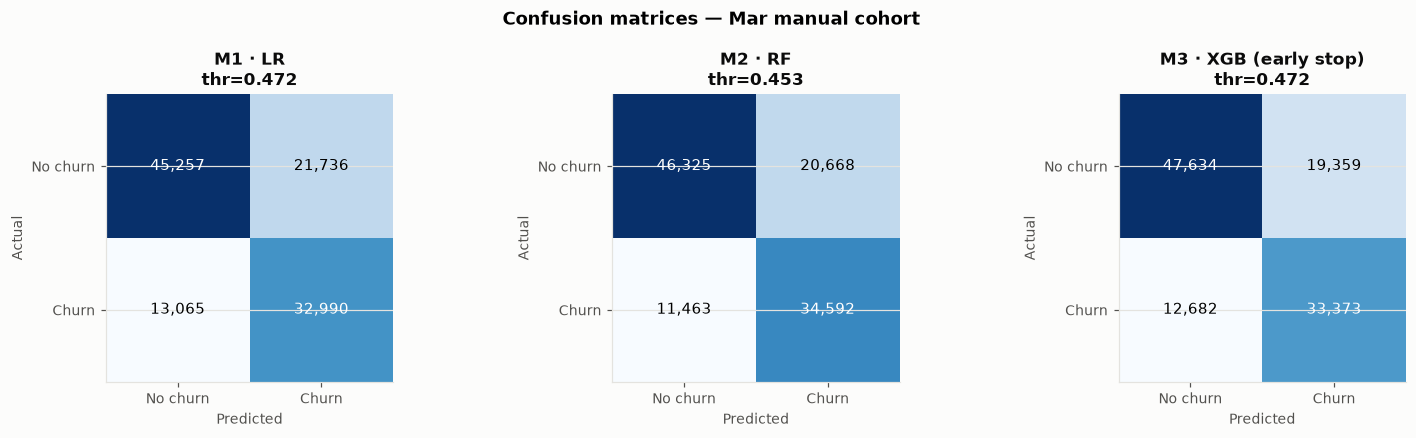

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (mid, proba, thr) in zip(axes, [
    ('M1', proba_test_m1, THRESHOLDS['M1']),
    ('M2', proba_test_m2, THRESHOLDS['M2']),
    ('M3', proba_test_m3, THRESHOLDS['M3']),
]):
    yhat = (proba >= thr).astype(int)
    cm   = confusion_matrix(y_test, yhat)
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i,j]:,}', ha='center', va='center',
                    color='white' if cm[i,j] > cm.max() / 2 else 'black', fontsize=10)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['No churn', 'Churn'])
    ax.set_yticklabels(['No churn', 'Churn'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_title(f'{mid} · {MODEL_NAMES[mid]}\nthr={thr:.3f}', fontweight='bold')

fig.suptitle('Confusion matrices — Mar manual cohort', fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(FIGS_DIR / 'w1_manual_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
baseline_pr = float(y_test.mean())

for mid, proba in [('M1', proba_test_m1), ('M2', proba_test_m2), ('M3', proba_test_m3)]:
    color = COLORS_MODEL[mid]
    label = MODEL_NAMES[mid]
    # ROC
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val     = roc_auc_score(y_test, proba)
    axes[0].plot(fpr, tpr, color=color, lw=1.8, label=f'{label}  AUC={auc_val:.3f}')
    # PR
    p, r, _ = precision_recall_curve(y_test, proba)
    ap      = average_precision_score(y_test, proba)
    axes[1].plot(r, p, color=color, lw=1.8, label=f'{label}  AP={ap:.3f}')

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC curve — Mar manual', fontweight='bold')
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)

axes[1].axhline(baseline_pr, color='gray', ls='--', lw=1, label=f'baseline ({baseline_pr:.2%})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall curve — Mar manual', fontweight='bold')
axes[1].set_ylim(0, 1); axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)

plt.suptitle('LR / RF / XGB (early stop) · 59 features · manual segment', fontsize=12)
plt.tight_layout()
fig.savefig(FIGS_DIR / 'w1_manual_roc_pr.png', dpi=150, bbox_inches='tight')
plt.show()


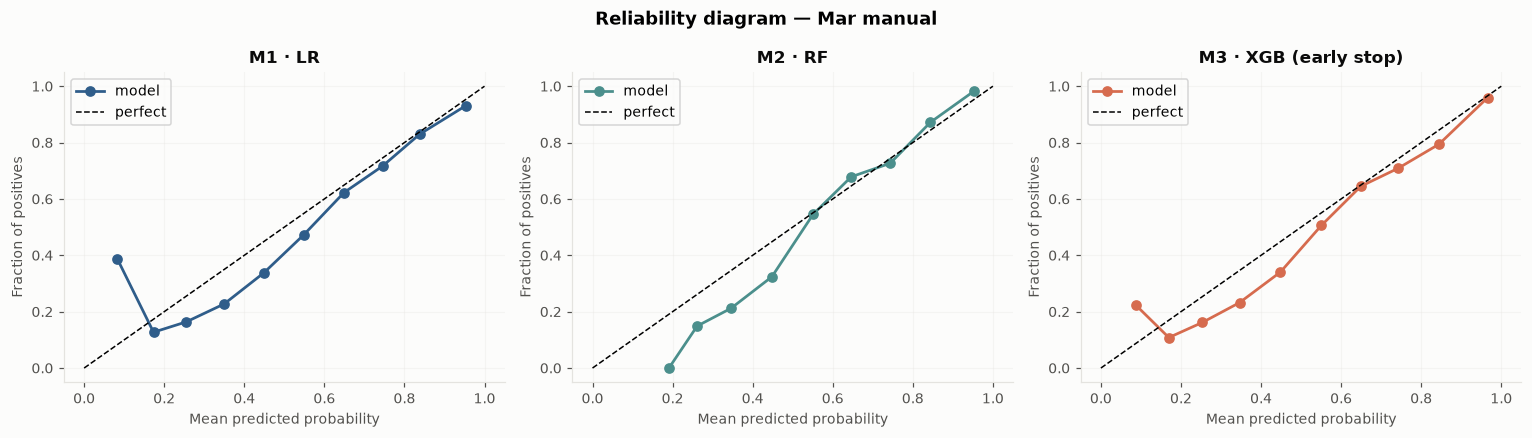

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (mid, proba) in zip(axes, [
    ('M1', proba_test_m1), ('M2', proba_test_m2), ('M3', proba_test_m3)
]):
    frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy='uniform')
    ax.plot(mean_pred, frac_pos, 'o-', color=COLORS_MODEL[mid], lw=1.8, label='model')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect')
    ax.set_title(f'{mid} · {MODEL_NAMES[mid]}', fontweight='bold')
    ax.set_xlabel('Mean predicted probability')
    ax.set_ylabel('Fraction of positives')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.suptitle('Reliability diagram — Mar manual', fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(FIGS_DIR / 'w1_manual_reliability.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Save models and artifacts

The development models (fitted on all February manual) are saved with their preprocessing.
M1 and M2 include their fitted pipeline. M3 stores the preprocessor and XGBClassifier separately
since it was not wrapped in a Pipeline.

```text
artifacts/sherlock_w1_manual/
  models/
    M1.joblib
    M2.joblib
    M3.joblib
  metrics/
    test_metrics.csv
    test_metrics_at_05.csv
  run_config.json
```

In [18]:
ARTIFACTS_DIR = ROOT / 'w1' / 'artifacts' / 'sherlock_w1_manual'
(ARTIFACTS_DIR / 'models').mkdir(parents=True, exist_ok=True)
(ARTIFACTS_DIR / 'metrics').mkdir(parents=True, exist_ok=True)

joblib.dump(pipe_m1_dev,  ARTIFACTS_DIR / 'models' / 'M1.joblib')
joblib.dump(pipe_m2_dev,  ARTIFACTS_DIR / 'models' / 'M2.joblib')
joblib.dump({'preprocessor': prep_m3_dev, 'model': xgb_m3_dev},
            ARTIFACTS_DIR / 'models' / 'M3.joblib')

test_metrics.to_csv(   ARTIFACTS_DIR / 'metrics' / 'test_metrics.csv',       index=False)
test_metrics_05.to_csv(ARTIFACTS_DIR / 'metrics' / 'test_metrics_at_05.csv', index=False)

run_cfg = {
    'seed': SEED, 'smoke_test': SMOKE_TEST,
    'lr_c': LR_C,
    'rf_n_estimators': RF_N_ESTIMATORS, 'rf_max_depth': RF_MAX_DEPTH,
    'rf_min_samples_leaf': RF_MIN_SAMPLES_LEAF,
    'xgb_n_estimators': XGB_N_ESTIMATORS, 'xgb_lr': XGB_LR,
    'xgb_max_depth': XGB_MAX_DEPTH, 'xgb_early_stop': XGB_EARLY_STOP,
    'xgb_best_iteration': M3_BEST_ITER,
    'winner': WINNER,
    'thresholds': {k: round(v, 5) for k, v in THRESHOLDS.items()},
    'tune_log_loss': {k: round(v, 5) for k, v in TUNE_LL.items()},
    'env': ENV,
}
(ARTIFACTS_DIR / 'run_config.json').write_text(json.dumps(run_cfg, indent=2))

print('Models and artifacts saved in:', ARTIFACTS_DIR.resolve())

Models and artifacts saved in: C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops\w1\artifacts\sherlock_w1_manual
